In [1]:
import sys, platform, multiprocessing

print ("Python    :", sys.version)
print ("Platform  :", platform.platform())
print ("CPU Cores :", multiprocessing.cpu_count())

for nama in ["pandas", "numpy", "pyarrow", "matplotlib"]:
  try:
    mod =__import__(nama)
    print(f"{nama:11s}: {mod.__version__}")
  except ImportError:
    print(f"{nama:11s}: BELUM TERPASANG")

Python    : 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
Platform  : Linux-6.6.122+-x86_64-with-glibc2.39
CPU Cores : 2
pandas     : 2.2.3
numpy      : 2.1.3
pyarrow    : 23.0.1
matplotlib : 3.10.0


In [2]:
!free -h        # kapasitas dan sisa RAM
!df -h /content # kapasitas dan sisa disk runtime
!java -version  # dibutuhkan PySpark pada langkah K-8

               total        used        free      shared  buff/cache   available
Mem:            12Gi       984Mi       8.8Gi       2.2Mi       3.2Gi        11Gi
Swap:             0B          0B          0B
Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   21G   88G  20% /
[0.023s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.023s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [3]:
from google.colab import drive
drive.mount("/content/drive")  # ikuti dialog izin yang muncul

import os

DIR_KERJA = "/content/data"  # sementara, cepat
DIR_SIMPAN = "/content/drive/MyDrive/BigData/Praktikum1"  # permanen

os.makedirs(DIR_KERJA, exist_ok=True)
os.makedirs(DIR_SIMPAN, exist_ok=True)

print(os.listdir(DIR_SIMPAN))

Mounted at /content/drive
[]


In [4]:
import time, os, psutil

proses = psutil.Process(os.getpid())
catatan = []  # menyimpan hasil pengukuran untuk dibandingkan nanti

def rss_mb():
    return proses.memory_info().rss / 1024**2

def ukur(label, fungsi):
    """Menjalankan fungsi tanpa argumen, mencatat durasi dan pertumbuhan memori."""
    m0, t0 = rss_mb(), time.perf_counter()

    hasil = fungsi()

    detik = time.perf_counter() - t0
    delta = rss_mb() - m0

    catatan.append({
        "langkah": label,
        "detik": round(detik, 2),
        "delta_rss_mb": round(delta, 1)
    })

    print(f"[{label}] {detik:.2f} s | RSS {delta:+.1f} MB")

    return hasil

In [5]:
import urllib.request

URL = (
    "https://d37ci6vzurychx.cloudfront.net/trip-data/"
    "yellow_tripdata_2023-01.parquet"
)

PATH = os.path.join(
    DIR_KERJA,
    "yellow_tripdata_2023-01.parquet"
)

if not os.path.exists(PATH):
    ukur(
        "unduh dataset",
        lambda: urllib.request.urlretrieve(URL, PATH)
    )

print(
    "Ukuran file:",
    round(os.path.getsize(PATH) / 1024**2, 1),
    "MB"
)

[unduh dataset] 1.20 s | RSS +2.0 MB
Ukuran file: 45.5 MB


In [6]:
import pyarrow.parquet as pq

meta = pq.ParquetFile(PATH).metadata

print("Jumlah baris :", f"{meta.num_rows:,}")
print("Jumlah kolom :", meta.num_columns)
print("Row group    :", meta.num_row_groups)
print("Nama kolom   :", pq.ParquetFile(PATH).schema.names)

Jumlah baris : 3,066,766
Jumlah kolom : 19
Row group    : 1
Nama kolom   : ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'airport_fee']


In [7]:
import numpy as np
import pandas as pd

def bangkitkan_sintetis(n=5_000_000, seed=42):
    rng = np.random.default_rng(seed)

    awal = pd.Timestamp("2023-01-01")

    pickup = awal + pd.to_timedelta(
        rng.integers(0, 31*24*60, n),
        unit="m"
    )

    durasi = rng.integers(1, 90, n)

    return pd.DataFrame({
        "tpep_pickup_datetime": pickup,
        "tpep_dropoff_datetime":
            pickup + pd.to_timedelta(durasi, unit="m"),
        "passenger_count":
            rng.integers(1, 5, n).astype("float64"),
        "trip_distance":
            np.round(rng.gamma(2.0, 1.6, n), 2),
        "payment_type":
            rng.integers(1, 6, n).astype("int64"),
        "fare_amount":
            np.round(rng.gamma(4.0, 3.0, n), 2),
        "tip_amount":
            np.round(rng.gamma(1.5, 1.2, n), 2),
    }).assign(
        total_amount=lambda d:
            (d.fare_amount + d.tip_amount + 3.0).round(2)
    )


if not os.path.exists(PATH):
    bangkitkan_sintetis().to_parquet(
        PATH,
        index=False
    )
    print("Dataset sintetis dibuat di", PATH)

In [8]:
import pandas as pd

KOLOM = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "payment_type",
    "fare_amount",
    "tip_amount",
    "total_amount"
]

penuh = ukur(
    "baca semua kolom",
    lambda: pd.read_parquet(PATH)
)

print("Dimensi:", penuh.shape)

print(
    "Memori :",
    round(
        penuh.memory_usage(deep=True).sum() / 1024**2,
        1
    ),
    "MB"
)

[baca semua kolom] 1.82 s | RSS +496.0 MB
Dimensi: (3066766, 19)
Memori : 565.6 MB


In [9]:
del penuh

import gc
gc.collect()

df = ukur(
    "baca kolom terpilih",
    lambda: pd.read_parquet(
        PATH,
        columns=KOLOM
    )
)

print("Dimensi:", df.shape)

print(
    "Memori :",
    round(
        df.memory_usage(deep=True).sum() / 1024**2,
        1
    ),
    "MB"
)

df.head()

[baca kolom terpilih] 0.56 s | RSS +209.6 MB
Dimensi: (3066766, 8)
Memori : 187.2 MB


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount
0,2023-01-01 00:32:10,2023-01-01 00:40:36,1.0,0.97,2,9.3,0.00,14.30
1,2023-01-01 00:55:08,2023-01-01 01:01:27,1.0,1.10,1,7.9,4.00,16.90
2,2023-01-01 00:25:04,2023-01-01 00:37:49,1.0,2.51,1,14.9,15.00,34.90
3,2023-01-01 00:03:48,2023-01-01 00:13:25,0.0,1.90,1,12.1,0.00,20.85
4,2023-01-01 00:10:29,2023-01-01 00:21:19,1.0,1.43,1,11.4,3.28,19.68


In [10]:
df.info(memory_usage="deep")

(
    df.memory_usage(deep=True)
      .sort_values(ascending=False)
      / 1024**2
)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3066766 entries, 0 to 3066765
Data columns (total 8 columns):
 #   Column                 Dtype         
---  ------                 -----         
 0   tpep_pickup_datetime   datetime64[us]
 1   tpep_dropoff_datetime  datetime64[us]
 2   passenger_count        float64       
 3   trip_distance          float64       
 4   payment_type           int64         
 5   fare_amount            float64       
 6   tip_amount             float64       
 7   total_amount           float64       
dtypes: datetime64[us](2), float64(5), int64(1)
memory usage: 187.2 MB


,0
tpep_pickup_datetime,23.397568
payment_type,23.397568
tpep_dropoff_datetime,23.397568
passenger_count,23.397568
trip_distance,23.397568
tip_amount,23.397568
fare_amount,23.397568
total_amount,23.397568
Index,0.000126


In [11]:
sebelum = (
    df.memory_usage(deep=True).sum()
    / 1024**2
)

df["passenger_count"] = pd.to_numeric(
    df["passenger_count"],
    downcast="float"
)

df["payment_type"] = (
    df["payment_type"]
      .astype("int8")
      .astype("category")
)

for kol in [
    "trip_distance",
    "fare_amount",
    "tip_amount",
    "total_amount"
]:
    df[kol] = pd.to_numeric(
        df[kol],
        downcast="float"
    )

sesudah = (
    df.memory_usage(deep=True).sum()
    / 1024**2
)

print(
    f"{sebelum:.1f} MB -> {sesudah:.1f} MB "
    f"(hemat {100*(1-sesudah/sebelum):.1f}%)"
)

df.dtypes

187.2 MB -> 119.9 MB (hemat 35.9%)


,0
tpep_pickup_datetime,datetime64[us]
tpep_dropoff_datetime,datetime64[us]
passenger_count,float32
trip_distance,float64
payment_type,category
fare_amount,float32
tip_amount,float32
total_amount,float32


In [12]:
df["durasi_menit"] = (
    (
        df["tpep_dropoff_datetime"]
        - df["tpep_pickup_datetime"]
    )
    .dt.total_seconds()
    / 60
)

print(
    df[
        [
            "trip_distance",
            "durasi_menit",
            "total_amount"
        ]
    ].describe()
)

print(
    "\nNilai kosong per kolom:\n",
    df.isna().sum()
)

       trip_distance  durasi_menit  total_amount
count   3.066766e+06  3.066766e+06  3.066766e+06
mean    3.847342e+00  1.566900e+01  2.702038e+01
std     2.495838e+02  4.259435e+01  2.212666e+01
min     0.000000e+00 -2.920000e+01 -7.510000e+02
25%     1.060000e+00  7.116667e+00  1.540000e+01
50%     1.800000e+00  1.151667e+01  2.016000e+01
75%     3.330000e+00  1.830000e+01  2.870000e+01
max     2.589281e+05  1.002918e+04  1.169400e+03

Nilai kosong per kolom:
 tpep_pickup_datetime         0
tpep_dropoff_datetime        0
passenger_count          71743
trip_distance                0
payment_type                 0
fare_amount                  0
tip_amount                   0
total_amount                 0
durasi_menit                 0
dtype: int64


In [13]:
anomali = {
    "jarak <= 0":
        (df["trip_distance"] <= 0).sum(),

    "durasi <= 0":
        (df["durasi_menit"] <= 0).sum(),

    "durasi > 180 menit":
        (df["durasi_menit"] > 180).sum(),

    "total_amount <= 0":
        (df["total_amount"] <= 0).sum(),
}

for k, v in anomali.items():
    print(
        f"{k:22s}: {v:,} baris "
        f"({100*v/len(df):.2f}%)"
    )

jarak <= 0            : 45,862 baris (1.50%)
durasi <= 0           : 1,121 baris (0.04%)
durasi > 180 menit    : 3,048 baris (0.10%)
total_amount <= 0     : 25,772 baris (0.84%)


In [14]:
layak = (
    (df["trip_distance"] > 0)
    & (df["trip_distance"] < 100)
    & (df["durasi_menit"].between(1, 180))
    & (df["total_amount"] > 0)
)

bersih = df.loc[layak].copy()

print(
    f"{len(df):,} baris -> "
    f"{len(bersih):,} baris "
    f"(dibuang {len(df)-len(bersih):,})"
)

3,066,766 baris -> 2,986,911 baris (dibuang 79,855)


In [15]:
CSV = os.path.join(
    DIR_KERJA,
    "trips.csv"
)

ukur(
    "tulis CSV",
    lambda: bersih.to_csv(
        CSV,
        index=False
    )
)

print(
    "Parquet:",
    round(
        os.path.getsize(PATH) / 1024**2,
        1
    ),
    "MB"
)

print(
    "CSV     :",
    round(
        os.path.getsize(CSV) / 1024**2,
        1
    ),
    "MB"
)

[tulis CSV] 39.76 s | RSS +5.2 MB
Parquet: 45.5 MB
CSV     : 226.2 MB


In [16]:
def agregasi_bertahap(path, ukuran_chunk=500_000):
    jumlah_baris = 0
    total_nilai = 0.0
    per_jam = {}

    potongan = pd.read_csv(
        path,
        usecols=[
            "tpep_pickup_datetime",
            "total_amount"
        ],
        parse_dates=[
            "tpep_pickup_datetime"
        ],
        chunksize=ukuran_chunk
    )

    for chunk in potongan:
        jumlah_baris += len(chunk)

        total_nilai += (
            chunk["total_amount"].sum()
        )

        for jam, sub in chunk.groupby(
            chunk["tpep_pickup_datetime"].dt.hour
        ):
            n, nilai = per_jam.get(
                jam,
                (0, 0.0)
            )

            per_jam[jam] = (
                n + len(sub),
                nilai + sub["total_amount"].sum()
            )

    return jumlah_baris, total_nilai, per_jam

In [17]:
baris, total, per_jam_chunk = ukur(
    "agregasi chunking",
    lambda: agregasi_bertahap(CSV)
)

print(
    f"{baris:,} baris | "
    f"rata-rata total_amount = "
    f"{total/baris:.2f}"
)

[agregasi chunking] 4.30 s | RSS +19.2 MB
2,986,911 baris | rata-rata total_amount = 27.33


In [18]:
!pip install -q pyspark==3.5.1
!java -version

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dataproc-spark-connect 1.1.0 requires pyspark[connect]~=4.0.0, but you have pyspark 3.5.1 which is incompatible.
[0.021s][warning][os,container] Cgroup memory controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
[0.021s][warning][os,container] Cgroup cpu controller path at '/sys/fs/cgroup' seems to have moved to '/../../jupyter-children', detected limits won't be accurate
openjdk version "21.0.12.1" 2026-08-18
OpenJDK Runtime Environment (build 21.0.12.1+1-1-24.04.4-Ubuntu)
OpenJDK 64-Bit Server VM (build 21.0.12.1+1-1-24.04.4-Ubuntu, mixed mode, sharing)


In [19]:
from pyspark.sql import SparkSession, functions as F

spark = (
    SparkSession.builder
    .appName("BD-P01")
    .master("local[*]")  # semua core mesin
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

spark.sparkContext.setLogLevel("WARN")

print("Spark:", spark.version)

Spark: 3.5.1


In [20]:
sdf = spark.read.parquet(PATH)

sdf.printSchema()

print(
    "Jumlah baris:",
    ukur(
        "spark count",
        lambda: sdf.count()
    )
)

root
 |-- VendorID: long (nullable = true)
 |-- tpep_pickup_datetime: timestamp_ntz (nullable = true)
 |-- tpep_dropoff_datetime: timestamp_ntz (nullable = true)
 |-- passenger_count: double (nullable = true)
 |-- trip_distance: double (nullable = true)
 |-- RatecodeID: double (nullable = true)
 |-- store_and_fwd_flag: string (nullable = true)
 |-- PULocationID: long (nullable = true)
 |-- DOLocationID: long (nullable = true)
 |-- payment_type: long (nullable = true)
 |-- fare_amount: double (nullable = true)
 |-- extra: double (nullable = true)
 |-- mta_tax: double (nullable = true)
 |-- tip_amount: double (nullable = true)
 |-- tolls_amount: double (nullable = true)
 |-- improvement_surcharge: double (nullable = true)
 |-- total_amount: double (nullable = true)
 |-- congestion_surcharge: double (nullable = true)
 |-- airport_fee: double (nullable = true)

[spark count] 3.64 s | RSS +0.0 MB
Jumlah baris: 3066766


In [21]:
sdf_bersih = (
    sdf
    .withColumn(
        "durasi_menit",
        (
            F.unix_timestamp(F.col("tpep_dropoff_datetime"))
            - F.unix_timestamp(F.col("tpep_pickup_datetime"))
        ) / 60
    )
    .filter(
        (F.col("trip_distance") > 0)
        & (F.col("trip_distance") < 100)
    )
    .filter(
        (F.col("durasi_menit") >= 1)
        & (F.col("durasi_menit") <= 180)
    )
    .filter(
        F.col("total_amount") > 0
    )
)

In [22]:
hasil_spark = (
    sdf_bersih
    .withColumn(
        "jam",
        F.hour("tpep_pickup_datetime")
    )
    .groupBy("jam")
    .agg(
        F.count("*").alias("jumlah"),
        F.round(
            F.avg("trip_distance"),
            2
        ).alias("rata_jarak"),
        F.round(
            F.avg("total_amount"),
            2
        ).alias("rata_tarif")
    )
    .orderBy("jam")
)

ukur(
    "spark agregasi",
    lambda: hasil_spark.show(
        24,
        truncate=False
    )
)

+---+------+----------+----------+
|jam|jumlah|rata_jarak|rata_tarif|
+---+------+----------+----------+
|0  |82289 |4.04      |28.86     |
|1  |57766 |3.53      |26.45     |
|2  |40445 |3.28      |25.06     |
|3  |26146 |3.58      |26.26     |
|4  |16618 |4.79      |31.72     |
|5  |16940 |6.03      |36.75     |
|6  |42300 |4.8       |30.63     |
|7  |84569 |3.69      |26.89     |
|8  |114064|3.08      |25.21     |
|9  |127988|3.09      |25.51     |
|10 |140230|3.13      |25.53     |
|11 |150539|3.0       |25.16     |
|12 |165714|3.11      |25.61     |
|13 |174183|3.29      |26.43     |
|14 |186741|3.57      |28.04     |
|15 |191392|3.41      |27.42     |
|16 |190689|3.51      |29.58     |
|17 |204399|3.3       |28.62     |
|18 |210858|2.94      |26.69     |
|19 |188347|3.25      |27.43     |
|20 |161789|3.44      |26.98     |
|21 |157770|3.61      |27.59     |
|22 |143800|3.85      |28.61     |
|23 |111335|4.23      |29.98     |
+---+------+----------+----------+

[spark agregasi] 8.

In [23]:
sdf_bersih.createOrReplaceTempView("trips")

spark.sql("""
    SELECT
        payment_type,
        COUNT(*) AS jumlah,
        ROUND(AVG(total_amount), 2) AS rata_tarif,
        ROUND(AVG(tip_amount), 2) AS rata_tip
    FROM trips
    GROUP BY payment_type
    ORDER BY jumlah DESC
""").show()

+------------+-------+----------+--------+
|payment_type| jumlah|rata_tarif|rata_tip|
+------------+-------+----------+--------+
|           1|2385064|      28.1|    4.16|
|           2| 512987|     23.58|     0.0|
|           0|  64106|     29.82|    4.06|
|           4|  15570|     24.11|    0.02|
|           3|   9184|     22.63|     0.0|
+------------+-------+----------+--------+



In [24]:
hasil_spark.explain()


== Physical Plan ==
AdaptiveSparkPlan isFinalPlan=false
+- Sort [jam#84 ASC NULLS FIRST], true, 0
   +- Exchange rangepartitioning(jam#84 ASC NULLS FIRST, 8), ENSURE_REQUIREMENTS, [plan_id=206]
      +- HashAggregate(keys=[jam#84], functions=[count(1), avg(trip_distance#4), avg(total_amount#16)])
         +- Exchange hashpartitioning(jam#84, 8), ENSURE_REQUIREMENTS, [plan_id=203]
            +- HashAggregate(keys=[jam#84], functions=[partial_count(1), partial_avg(trip_distance#4), partial_avg(total_amount#16)])
               +- Project [trip_distance#4, total_amount#16, hour(tpep_pickup_datetime#1, Some(Etc/UTC)) AS jam#84]
                  +- Filter ((((((isnotnull(trip_distance#4) AND isnotnull(total_amount#16)) AND (trip_distance#4 > 0.0)) AND (trip_distance#4 < 100.0)) AND ((cast((unix_timestamp(tpep_dropoff_datetime#2, yyyy-MM-dd HH:mm:ss, Some(Etc/UTC), false) - unix_timestamp(tpep_pickup_datetime#1, yyyy-MM-dd HH:mm:ss, Some(Etc/UTC), false)) as double) / 60.0) >= 1.0)) AND ((

In [25]:
spark.stop()

In [26]:
bersih["jam"] = (
    bersih["tpep_pickup_datetime"].dt.hour
)

agregasi = (
    bersih
    .groupby("jam")
    .agg(
        jumlah_perjalanan=("total_amount", "size"),
        rata_jarak=("trip_distance", "mean"),
        rata_durasi=("durasi_menit", "mean"),
        rata_tarif=("total_amount", "mean"),
        median_tarif=("total_amount", "median")
    )
    .round(2)
    .reset_index()
)

agregasi.to_csv(
    f"{DIR_SIMPAN}/agregasi_per_jam.csv",
    index=False
)

agregasi.to_parquet(
    f"{DIR_SIMPAN}/agregasi_per_jam.parquet",
    index=False
)

pd.DataFrame(catatan).to_csv(
    f"{DIR_SIMPAN}/pengukuran_kinerja.csv",
    index=False
)

agregasi

,jam,jumlah_perjalanan,rata_jarak,rata_durasi,rata_tarif,median_tarif
0,0,82289,4.04,13.57,28.860001,21.600000
1,1,57766,3.53,12.63,26.450001,21.200001
2,2,40445,3.28,12.07,25.059999,20.520000
3,3,26146,3.58,12.15,26.260000,21.000000
4,4,16618,4.79,13.52,31.719999,22.700001
5,5,16940,6.03,14.70,36.750000,22.040001
6,6,42300,4.80,14.49,30.629999,18.480000
7,7,84569,3.69,14.42,26.889999,18.480000
8,8,114064,3.08,14.33,25.209999,19.100000
9,9,127988,3.09,14.23,25.510000,19.250000


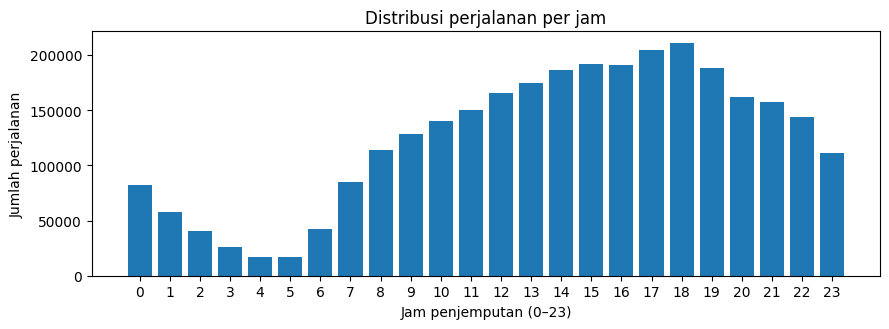

In [27]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 3.4))

ax.bar(
    agregasi["jam"],
    agregasi["jumlah_perjalanan"]
)

ax.set_xlabel("Jam penjemputan (0–23)")
ax.set_ylabel("Jumlah perjalanan")
ax.set_title("Distribusi perjalanan per jam")
ax.set_xticks(range(0, 24))

fig.tight_layout()

fig.savefig(
    f"{DIR_SIMPAN}/distribusi_per_jam.png",
    dpi=150
)

plt.show()

P. Latihan


In [28]:
# Mengambil 5 perjalanan dengan jarak terbesar
lima_terbesar = bersih.nlargest(
    5,
    "trip_distance"
)

# Menampilkan seluruh kolom dari 5 baris tersebut
display(lima_terbesar)

,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount,durasi_menit,jam
1748933,2023-01-19 16:29:36,2023-01-19 18:46:01,1.0,96.70,1,350.000000,50.0,440.750000,136.416667,16
526988,2023-01-07 04:29:56,2023-01-07 06:06:16,2.0,93.05,2,542.000000,0.0,564.049988,96.333333,4
2402193,2023-01-26 04:55:45,2023-01-26 07:18:50,1.0,92.60,1,262.500000,20.0,312.799988,143.083333,4
2902389,2023-01-31 07:04:24,2023-01-31 09:32:54,1.0,92.00,1,334.100006,10.0,368.149994,148.500000,7
927215,2023-01-11 14:23:55,2023-01-11 16:17:58,1.0,90.63,2,250.000000,0.0,272.299988,114.050000,14


In [29]:
# Pengujian dengan chunksize 100.000
hasil_100k = ukur(
    "chunking 100k",
    lambda: agregasi_bertahap(
        CSV,
        ukuran_chunk=100_000
    )
)

# Pengujian dengan chunksize 1.000.000
hasil_1m = ukur(
    "chunking 1m",
    lambda: agregasi_bertahap(
        CSV,
        ukuran_chunk=1_000_000
    )
)

# Menampilkan tabel perbandingan
pd.DataFrame(catatan).tail(2)


[chunking 100k] 5.27 s | RSS +6.3 MB
[chunking 1m] 3.86 s | RSS +68.1 MB


,langkah,detik,delta_rss_mb
7,chunking 100k,5.27,6.3
8,chunking 1m,3.86,68.1


In [30]:
# Membuat salinan data agar tidak mengubah DataFrame utama
df_tip = bersih.copy()

# Menghitung persentase tip
df_tip["persen_tip"] = (
    df_tip["tip_amount"]
    .div(df_tip["fare_amount"].where(
        df_tip["fare_amount"] != 0
    ))
    * 100
)

# Mengabaikan nilai yang tidak dapat dihitung
df_tip["persen_tip"] = df_tip["persen_tip"].replace(
    [float("inf"), float("-inf")],
    float("nan")
)

# Menghitung rata-rata persentase tip per payment_type
rata_tip = (
    df_tip
    .groupby("payment_type", observed=True)
    .agg(
        rata_persen_tip=("persen_tip", "mean"),
        jumlah_perjalanan=("persen_tip", "count")
    )
    .round(2)
    .reset_index()
)

display(rata_tip)

,payment_type,rata_persen_tip,jumlah_perjalanan
0,0,20.219999,64106
1,1,25.910000,2385053
2,2,0.000000,512885
3,3,0.020000,9145
4,4,0.150000,15542


In [31]:
import os
import time
import pandas as pd

path_snappy = f"{DIR_SIMPAN}/bersih_snappy.parquet"
path_gzip = f"{DIR_SIMPAN}/bersih_gzip.parquet"

hasil_kompresi = []

for kompresi, path in [
    ("snappy", path_snappy),
    ("gzip", path_gzip)
]:
    mulai = time.perf_counter()

    bersih.to_parquet(
        path,
        index=False,
        compression=kompresi
    )

    waktu_tulis = time.perf_counter() - mulai
    ukuran_mb = os.path.getsize(path) / 1024**2

    hasil_kompresi.append({
        "kompresi": kompresi,
        "ukuran_mb": round(ukuran_mb, 2),
        "waktu_tulis_detik": round(waktu_tulis, 2)
    })

perbandingan_kompresi = pd.DataFrame(
    hasil_kompresi
)

display(perbandingan_kompresi)

,kompresi,ukuran_mb,waktu_tulis_detik
0,snappy,53.27,1.91
1,gzip,41.87,41.13


In [34]:
from pyspark.sql import SparkSession, functions as F
import pandas as pd

# 1. Mengaktifkan kembali SparkSession
spark = (
    SparkSession.builder
    .appName("BD-P01")
    .master("local[*]")
    .config("spark.driver.memory", "4g")
    .config("spark.sql.shuffle.partitions", "8")
    .getOrCreate()
)

# 2. Membaca ulang dan membuat DataFrame Spark baru menggunakan sesi yang baru diaktifkan
sdf_baru = spark.read.parquet(PATH)
sdf_bersih_baru = (
    sdf_baru
    .withColumn(
        "durasi_menit",
        (
            F.unix_timestamp(F.col("tpep_dropoff_datetime"))
            - F.unix_timestamp(F.col("tpep_pickup_datetime"))
        ) / 60
    )
    .filter(
        (F.col("trip_distance") > 0)
        & (F.col("trip_distance") < 100)
    )
    .filter(
        (F.col("durasi_menit") >= 1)
        & (F.col("durasi_menit") <= 180)
    )
    .filter(
        F.col("total_amount") > 0
    )
)

# 3. Mendaftarkan ulang data bersih Spark sebagai tabel SQL
sdf_bersih_baru.createOrReplaceTempView("trips_bersih")

# Agregasi per jam dengan pandas
hasil_pandas = (
    bersih
    .assign(
        jam=bersih["tpep_pickup_datetime"].dt.hour
    )
    .groupby("jam")
    .agg(
        jumlah=("total_amount", "size")
    )
    .reset_index()
    .sort_values("jam")
)

# Agregasi per jam menggunakan Spark SQL
hasil_sql = spark.sql("""
    SELECT
        HOUR(tpep_pickup_datetime) AS jam,
        COUNT(*) AS jumlah
    FROM trips_bersih
    GROUP BY HOUR(tpep_pickup_datetime)
    ORDER BY jam
""")

# Mengubah hasil Spark menjadi pandas untuk dibandingkan
hasil_spark_pd = hasil_sql.toPandas()

# Membandingkan jumlah perjalanan
perbandingan = hasil_pandas.merge(
    hasil_spark_pd,
    on="jam",
    how="outer",
    suffixes=("_pandas", "_spark")
).fillna(0)

perbandingan["selisih"] = (
    perbandingan["jumlah_pandas"]
    - perbandingan["jumlah_spark"]
).abs()

display(perbandingan)

print(
    "Selisih maksimum:",
    perbandingan["selisih"].max()
)

,jam,jumlah_pandas,jumlah_spark,selisih
0,0,82289,82289,0
1,1,57766,57766,0
2,2,40445,40445,0
3,3,26146,26146,0
4,4,16618,16618,0
5,5,16940,16940,0
6,6,42300,42300,0
7,7,84569,84569,0
8,8,114064,114064,0
9,9,127988,127988,0


Selisih maksimum: 0


In [35]:
spark.stop()

Q.Tugas Praktikum

In [36]:
import os
import urllib.request
import pandas as pd
import pyarrow.parquet as pq

URL_JULI = (
    "https://d37ci6vzurychx.cloudfront.net/trip-data/"
    "yellow_tripdata_2023-07.parquet"
)

PATH_JULI = os.path.join(
    DIR_KERJA,
    "yellow_tripdata_2023-07.parquet"
)

if not os.path.exists(PATH_JULI):
    urllib.request.urlretrieve(URL_JULI, PATH_JULI)

meta_juli = pq.ParquetFile(PATH_JULI).metadata

print("Ukuran file:", round(os.path.getsize(PATH_JULI) / 1024**2, 2), "MB")
print("Jumlah baris:", f"{meta_juli.num_rows:,}")
print("Jumlah kolom:", meta_juli.num_columns)
print("Nama kolom:", pq.ParquetFile(PATH_JULI).schema.names)

Ukuran file: 46.12 MB
Jumlah baris: 2,907,108
Jumlah kolom: 19
Nama kolom: ['VendorID', 'tpep_pickup_datetime', 'tpep_dropoff_datetime', 'passenger_count', 'trip_distance', 'RatecodeID', 'store_and_fwd_flag', 'PULocationID', 'DOLocationID', 'payment_type', 'fare_amount', 'extra', 'mta_tax', 'tip_amount', 'tolls_amount', 'improvement_surcharge', 'total_amount', 'congestion_surcharge', 'Airport_fee']


In [37]:
KOLOM = [
    "tpep_pickup_datetime",
    "tpep_dropoff_datetime",
    "passenger_count",
    "trip_distance",
    "payment_type",
    "fare_amount",
    "tip_amount",
    "total_amount"
]

def muat_dan_bersihkan(path):
    data = pd.read_parquet(path, columns=KOLOM)

    data["durasi_menit"] = (
        data["tpep_dropoff_datetime"]
        - data["tpep_pickup_datetime"]
    ).dt.total_seconds() / 60

    layak = (
        data["tpep_pickup_datetime"].notna()
        & data["tpep_dropoff_datetime"].notna()
        & data["trip_distance"].between(0, 100, inclusive="neither")
        & data["durasi_menit"].between(1, 180)
        & data["total_amount"].gt(0)
    )

    return data.loc[layak].copy()

# Data Juli
bersih_juli = muat_dan_bersihkan(PATH_JULI)

print("Jumlah baris bersih Juli:", f"{len(bersih_juli):,}")
display(bersih_juli.head())

Jumlah baris bersih Juli: 2,817,657


,tpep_pickup_datetime,tpep_dropoff_datetime,passenger_count,trip_distance,payment_type,fare_amount,tip_amount,total_amount,durasi_menit
0,2023-07-01 00:29:59,2023-07-01 00:40:15,1.0,1.80,1,12.1,5.10,22.20,10.266667
1,2023-07-01 00:03:25,2023-07-01 00:23:44,1.0,2.31,2,19.1,0.00,24.10,20.316667
2,2023-07-01 00:38:29,2023-07-01 00:48:53,1.0,2.36,1,13.5,3.70,22.20,10.400000
3,2023-07-01 00:14:16,2023-07-01 00:29:13,1.0,4.36,1,19.8,4.96,29.76,14.950000
4,2023-07-01 00:11:15,2023-07-01 00:20:47,0.0,1.60,1,11.4,3.25,19.65,9.533333


In [38]:
# Pastikan data Januari dan Juli sudah dibersihkan
bersih_januari = bersih.copy()

def agregasi_jam(data, nama_bulan):
    return (
        data.assign(
            jam=data["tpep_pickup_datetime"].dt.hour
        )
        .groupby("jam")
        .agg(
            jumlah_perjalanan=("total_amount", "size"),
            rata_jarak=("trip_distance", "mean"),
            rata_tarif=("total_amount", "mean")
        )
        .round(2)
        .reset_index()
        .rename(columns={
            "jumlah_perjalanan": f"jumlah_{nama_bulan}",
            "rata_jarak": f"jarak_{nama_bulan}",
            "rata_tarif": f"tarif_{nama_bulan}"
        })
    )

jan = agregasi_jam(bersih_januari, "januari")
jul = agregasi_jam(bersih_juli, "juli")

perbandingan_bulan = jan.merge(
    jul,
    on="jam",
    how="outer"
).fillna(0).sort_values("jam")

display(perbandingan_bulan)

perbandingan_bulan.to_csv(
    f"{DIR_SIMPAN}/perbandingan_januari_juli.csv",
    index=False
)

,jam,jumlah_januari,jarak_januari,tarif_januari,jumlah_juli,jarak_juli,tarif_juli
0,0,82289,4.04,28.860001,85987,4.45,31.05
1,1,57766,3.53,26.450001,59980,4.04,28.64
2,2,40445,3.28,25.059999,40812,3.79,27.08
3,3,26146,3.58,26.260000,26000,4.02,27.92
4,4,16618,4.79,31.719999,16637,5.60,34.92
5,5,16940,6.03,36.750000,16913,6.67,39.74
6,6,42300,4.80,30.629999,38422,5.11,32.13
7,7,84569,3.69,26.889999,69358,4.10,28.60
8,8,114064,3.08,25.209999,103647,3.53,27.34
9,9,127988,3.09,25.510000,118788,3.40,27.28


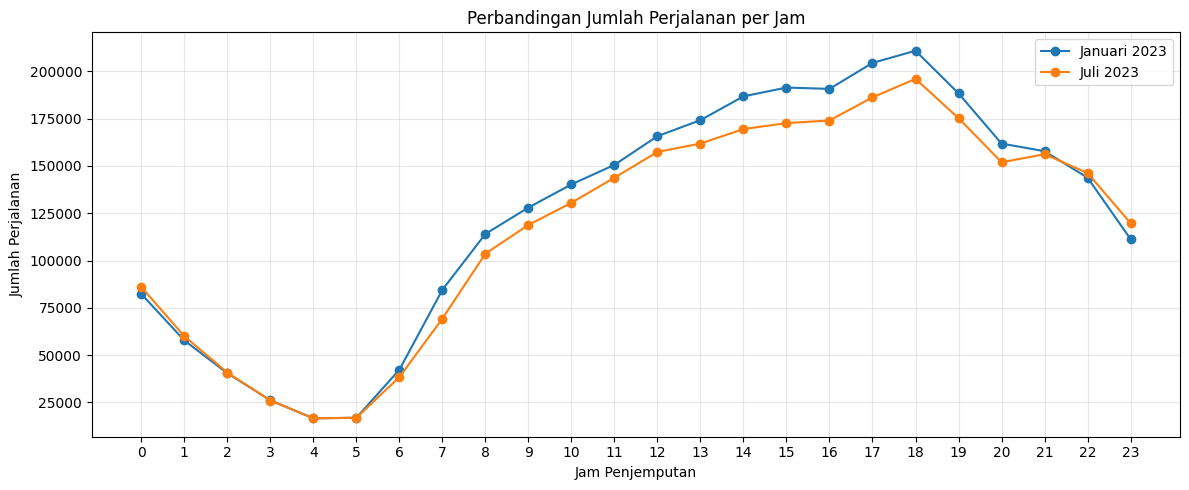

In [39]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    perbandingan_bulan["jam"],
    perbandingan_bulan["jumlah_januari"],
    marker="o",
    label="Januari 2023"
)

plt.plot(
    perbandingan_bulan["jam"],
    perbandingan_bulan["jumlah_juli"],
    marker="o",
    label="Juli 2023"
)

plt.title("Perbandingan Jumlah Perjalanan per Jam")
plt.xlabel("Jam Penjemputan")
plt.ylabel("Jumlah Perjalanan")
plt.xticks(range(24))
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{DIR_SIMPAN}/perbandingan_januari_juli.png",
    dpi=150
)

plt.show()

In [40]:
laporan_kinerja = pd.DataFrame(catatan)

display(
    laporan_kinerja.sort_values(
        "detik",
        ascending=False
    )
)

laporan_kinerja.to_csv(
    f"{DIR_SIMPAN}/pengukuran_kinerja.csv",
    index=False
)

,langkah,detik,delta_rss_mb
3,tulis CSV,39.76,5.2
6,spark agregasi,8.25,0.0
7,chunking 100k,5.27,6.3
4,agregasi chunking,4.30,19.2
8,chunking 1m,3.86,68.1
5,spark count,3.64,0.0
1,baca semua kolom,1.82,496.0
0,unduh dataset,1.20,2.0
2,baca kolom terpilih,0.56,209.6


In [41]:
termahal = laporan_kinerja.loc[
    laporan_kinerja["detik"].idxmax()
]

print("Langkah terlama:", termahal["langkah"])
print("Waktu:", termahal["detik"], "detik")
print("Perubahan RSS:", termahal["delta_rss_mb"], "MB")

Langkah terlama: tulis CSV
Waktu: 39.76 detik
Perubahan RSS: 5.2 MB
